### 0. Import required libraries

In [53]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

### 1. Import un-sampled dataset

In [54]:
dataset_path = 'US_Accidents_March23_sampled_500k.csv'
df = pd.read_csv(dataset_path)

### 2. Exploratory Data Analysis

In [55]:
# Get a quick overview of the dataset
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 46 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     500000 non-null  str    
 1   Source                 500000 non-null  str    
 2   Severity               500000 non-null  int64  
 3   Start_Time             500000 non-null  str    
 4   End_Time               500000 non-null  str    
 5   Start_Lat              500000 non-null  float64
 6   Start_Lng              500000 non-null  float64
 7   End_Lat                279623 non-null  float64
 8   End_Lng                279623 non-null  float64
 9   Distance(mi)           500000 non-null  float64
 10  Description            499999 non-null  str    
 11  Street                 499309 non-null  str    
 12  City                   499981 non-null  str    
 13  County                 500000 non-null  str    
 14  State                  500000 non-null  str    

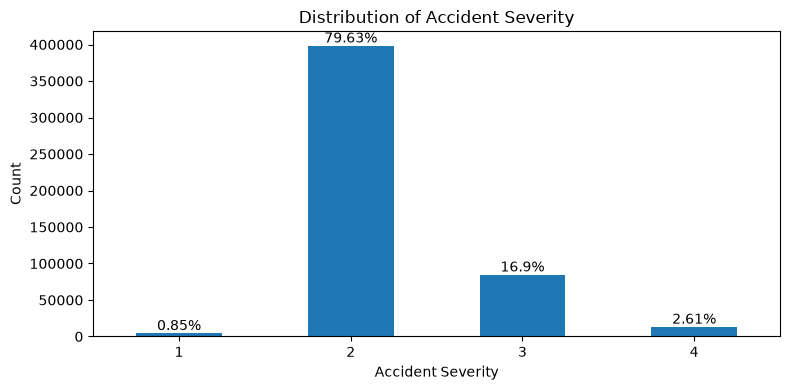

In [56]:
severity_counts = df['Severity'].value_counts().sort_index()
severity_pct = (severity_counts / len(df) * 100).round(2)
ax = severity_counts.plot(kind='bar', figsize=(8, 4), rot=0)
ax.set_xlabel('Accident Severity')
ax.set_ylabel('Count')
ax.set_title('Distribution of Accident Severity')
for i, (cnt, pct) in enumerate(zip(severity_counts, severity_pct)):
    ax.text(i, cnt, f'{pct}%', ha='center', va='bottom')
plt.tight_layout()
plt.show()

As mentioned in our proposal, severity is heavily imbalanced, with severity 2 making up roughly 80% of the records. We need to take this into consideration when choosing algorithms and metrics.

In [57]:
missing = df.isna().sum()
missing = pd.DataFrame({
    'missing': missing,
    'percent': (missing / len(df) * 100).round(2)
})
missing = missing[missing['missing'] > 0].sort_values('percent', ascending=False)
missing

,missing,percent
End_Lat,220377,44.08
End_Lng,220377,44.08
Precipitation(in),142616,28.52
Wind_Chill(F),129017,25.80
Wind_Speed(mph),36987,7.40
Visibility(mi),11291,2.26
Wind_Direction,11197,2.24
Humidity(%),11130,2.23
Weather_Condition,11101,2.22
Temperature(F),10466,2.09


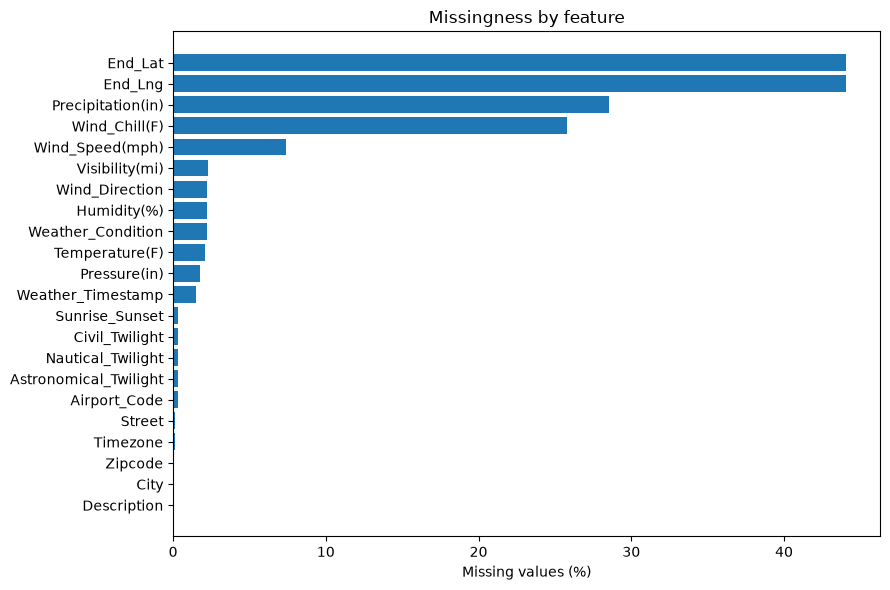

In [58]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(missing.index[::-1], missing['percent'][::-1])
ax.set_xlabel('Missing values (%)')
ax.set_title('Missingness by feature')
plt.tight_layout()
plt.show()

22 of the columns have missing values. `End_Lat` and `End_Lng` are the worst, missing in about 44% of records. `Precipitation(in)` (28.5%) and `Wind_Chill(F)` (25.8%) are the next most incomplete. The other weather features are missing in only about 2 to 7% of records. 

`Percipitation` is missing about 30% of the time, however, as you can see from the data below, missing values occured almost entirely under dry or cloudy conditions, so we believe it is safe to treat them as 0.

In [59]:
missing_precip = df['Precipitation(in)'].isna()
print("Weather conditions where precipitation is missing:")
print(df.loc[missing_precip, 'Weather_Condition'].value_counts(normalize=True).head(10).mul(100).round(1))
print("\nWeather conditions where precipitation is recorded:")
print(df.loc[~missing_precip, 'Weather_Condition'].value_counts(normalize=True).head(10).mul(100).round(1))

Weather conditions where precipitation is missing:
Weather_Condition
Clear               39.0
Overcast            16.0
Mostly Cloudy       14.9
Partly Cloudy       10.7
Scattered Clouds     9.5
Fair                 4.2
Haze                 1.4
Cloudy               0.9
Light Rain           0.7
Fog                  0.7
Name: proportion, dtype: float64

Weather conditions where precipitation is recorded:
Weather_Condition
Fair             45.1
Cloudy           14.6
Mostly Cloudy    12.8
Partly Cloudy     8.7
Light Rain        6.1
Light Snow        2.2
Fog               1.6
Rain              1.4
Overcast          1.0
Haze              0.9
Name: proportion, dtype: float64


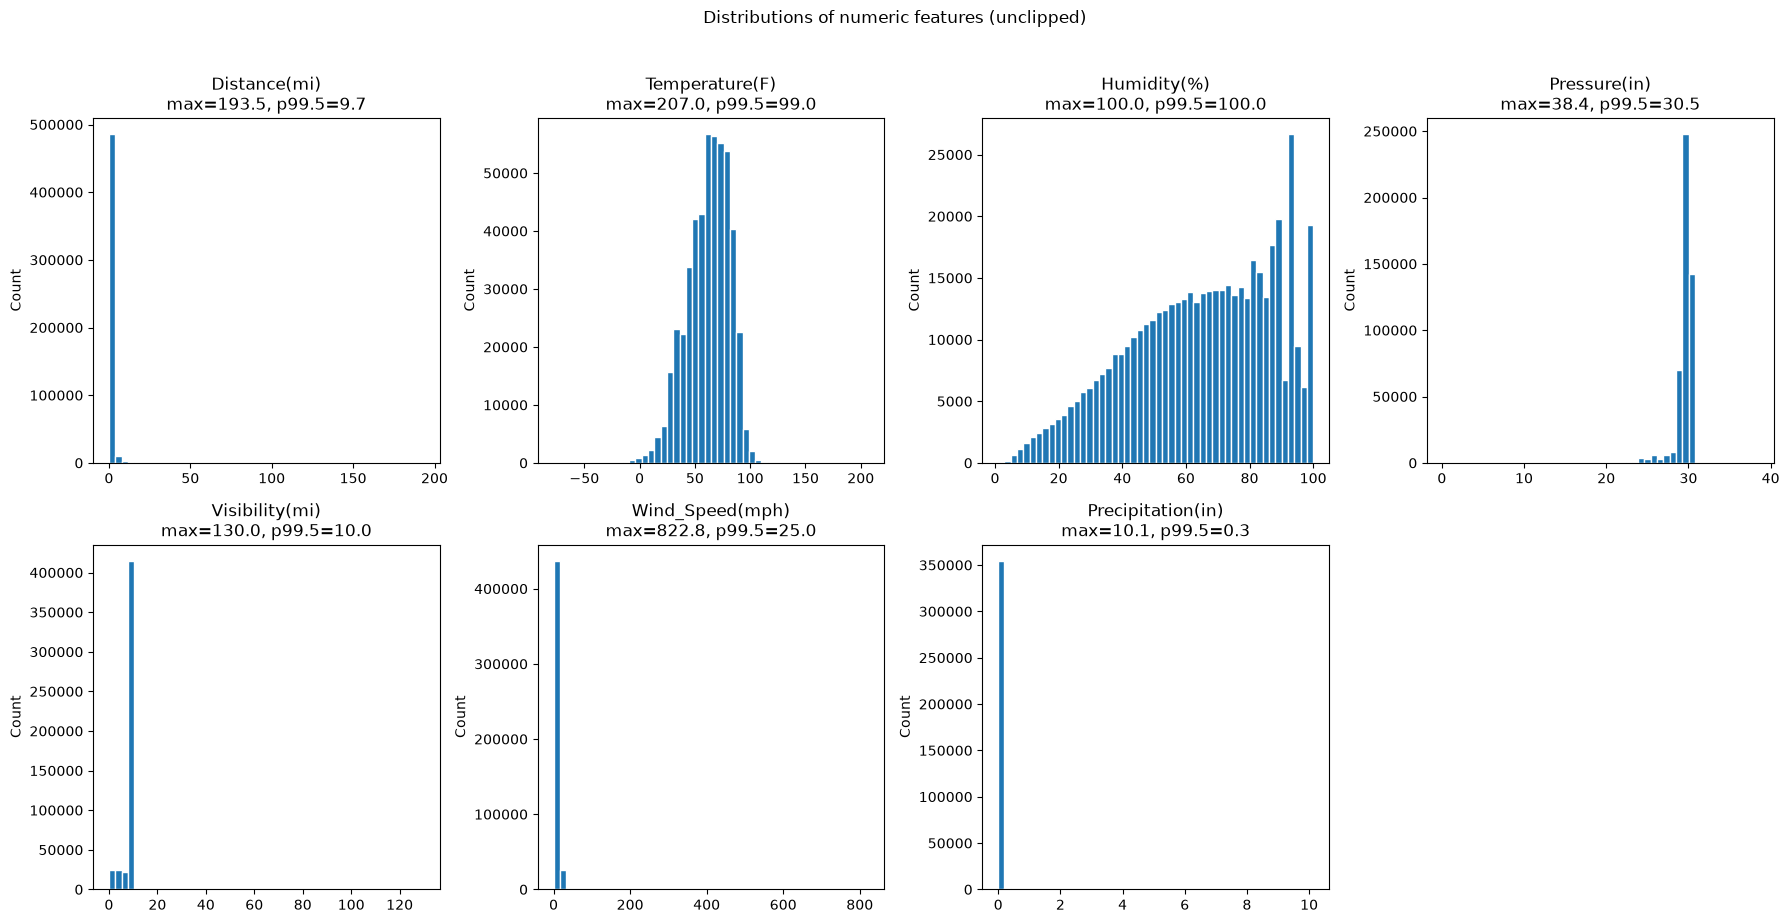

In [60]:
num_cols = ['Distance(mi)', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
            'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
num_cols = [c for c in num_cols if c in df.columns]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), num_cols):
    data = df[col].dropna()
    ax.hist(data, bins=50, edgecolor='white')
    ax.set_title(f'{col}\nmax={data.max():.1f}, p99.5={data.quantile(0.995):.1f}')
    ax.set_ylabel('Count')
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
plt.suptitle('Distributions of numeric features (unclipped)', y=1.02)
plt.tight_layout()
plt.show()

As you can see from the graphs above, much of the numerical data have outlier values, which cause the graphs to appear zoomed-out, and will later lead to issues when running our data mining algorithms. To help with this, during our data preprocessing we will remove the extreme outliers and keep only the data within the 99.5 percentile.

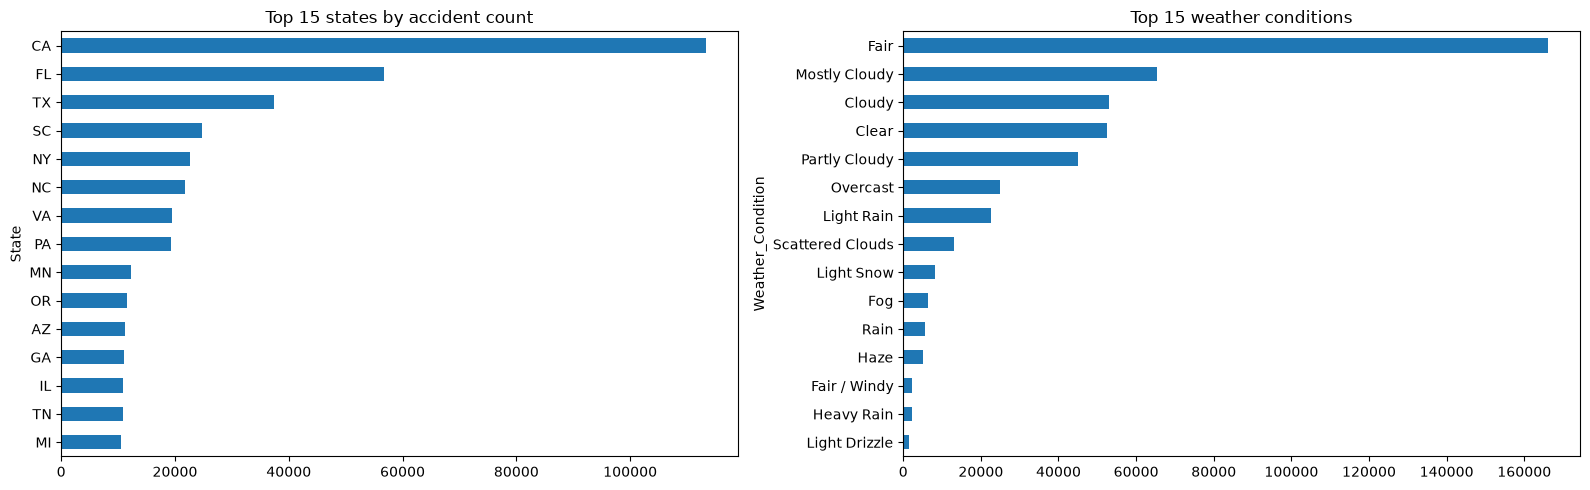

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df['State'].value_counts().head(15).plot(kind='barh', ax=axes[0])
axes[0].invert_yaxis()
axes[0].set_title('Top 15 states by accident count')

df['Weather_Condition'].value_counts().head(15).plot(kind='barh', ax=axes[1])
axes[1].invert_yaxis()
axes[1].set_title('Top 15 weather conditions')

plt.tight_layout()
plt.show()

Understandably, the more populated states have more counts within the dataset. It is important to keep in mind that we are not predicting accident *probability* but rather accident *severity*, so the imbalance should not neccessarily bias the Severity target. However, the Severity of an accident still may vary by state regardless. 

In [62]:
# Which boolean flags are rarely True?
bool_cols = df.select_dtypes(include='bool').columns
percent_true = (df[bool_cols].mean() * 100).round(2).sort_values()
print("Percent of records where each flag is True:")
print(percent_true.head(5))

Percent of records where each flag is True:
Roundabout         0.00
Turning_Loop       0.00
Bump               0.04
Traffic_Calming    0.09
No_Exit            0.25
dtype: float64


Roundabounts and Turning_loops are never true in the dataset, so they can be safely removed.

In [63]:
print(f"Total Unique Weather_Condition Values: {df['Weather_Condition'].nunique()}")
print((df['Weather_Condition'].value_counts(normalize=True).head(25) * 100).round(2))
shares = df['Weather_Condition'].value_counts(normalize=True).cumsum() * 100
n_99 = (shares < 99).sum() + 1
print(f"The top {n_99} weather conditions cover 99% of records with a weather value")

Total Unique Weather_Condition Values: 108
Weather_Condition
Fair                       33.96
Mostly Cloudy              13.38
Cloudy                     10.86
Clear                      10.71
Partly Cloudy               9.23
Overcast                    5.09
Light Rain                  4.65
Scattered Clouds            2.67
Light Snow                  1.68
Fog                         1.32
Rain                        1.13
Haze                        1.02
Fair / Windy                0.48
Heavy Rain                  0.44
Light Drizzle               0.30
Thunder in the Vicinity     0.24
Mostly Cloudy / Windy       0.23
Cloudy / Windy              0.22
T-Storm                     0.22
Snow                        0.20
Thunder                     0.19
Light Rain with Thunder     0.17
Smoke                       0.16
Wintry Mix                  0.16
Partly Cloudy / Windy       0.13
Name: proportion, dtype: float64
The top 27 weather conditions cover 99% of records with a weather value


As you can see, the `Weather_Condition` feature has 108 unique values, however, the top 27 conditions cover 99% of the records. Therefore, to reduce the number of category options, we can keep the top 27 conditions, and put the rest into an "other" option.

In [64]:
# Does the type of road affect severity? (e.g. "I-5 N" is an interstate)
high = df['Severity'] >= 3
street = df['Street'].fillna('')
road_type = pd.Series(np.select(
    [street.str.contains(r'\bI-\s?\d'),
     street.str.contains(r'\b(?:US-|Hwy|Highway|Fwy|Freeway|Expy|Expressway|Pkwy|Parkway|Tpke|Turnpike)', case=False)],
    ['Interstate', 'Highway'],
    default='Other'
), index=df.index)

# For each road type, its share of records and the percent that are severity 3 or 4
print(pd.DataFrame({
    'percent_of_records': road_type.value_counts(normalize=True).mul(100).round(1),
    'percent_severity_3_or_4': high.groupby(road_type).mean().mul(100).round(1),
}))

            percent_of_records  percent_severity_3_or_4
Highway                   19.7                     19.6
Interstate                24.9                     36.0
Other                     55.4                     12.1


While `Street` has too many unique values to encode directly, the street name tells us the type of road. Accidents on interstates are severity 3 or 4 about 36% of the time, nearly double the overall rate of 19.5%. Therefore, we will replace `Street` with one-hot encoded values for `Highway`, `Interstate`, or `Other`.

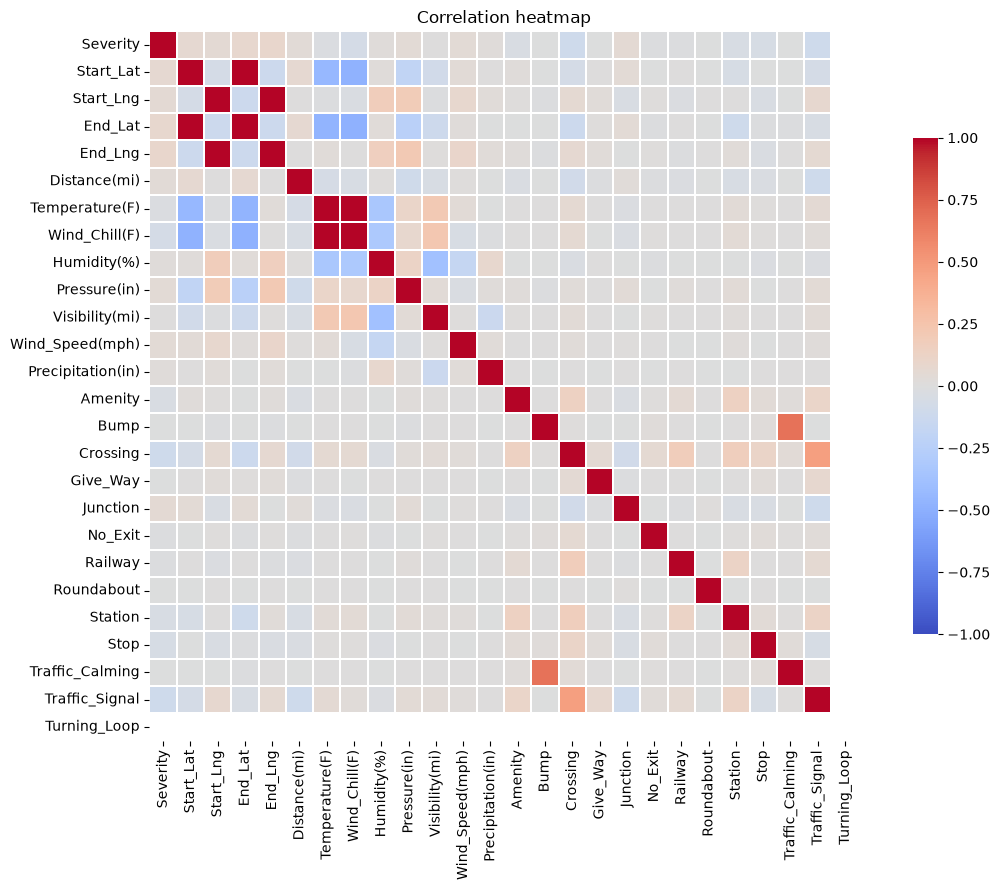

In [65]:
corr_df = pd.concat([df.select_dtypes(include='number'),
                     df.select_dtypes(include='bool').astype(int)], axis=1)
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.3, cbar_kws={'shrink': 0.7}, ax=ax)
ax.set_title('Correlation heatmap')
plt.tight_layout()
plt.show()

`Temperature(F)` and `Wind_Chill(F)` are almost perfectly correlated, as are the start and end coordinates (`Start_Lat`/`End_Lat`, `Start_Lng`/`End_Lng`). These pairs are redundant, which supports dropping `Wind_Chill(F)`, `End_Lat` and `End_Lng`.

Among the remaining features, the strongest correlations are moderate: `Crossing` with `Traffic_Signal`, and `Bump` with `Traffic_Calming`.

No feature has a strong linear correlation with `Severity`, so severity is not explained by any single factor.

### 3. Data Transformation & Preprocessing

We start our data transformation by parsing the string timestamps into numerical data:

In [66]:
# Create new features

# Convert the String timestamps into pandas datetime objects
df['Start_Time'] = pd.to_datetime(df['Start_Time'], format='mixed', errors='coerce')
df['End_Time'] = pd.to_datetime(df['End_Time'], format='mixed', errors='coerce')

# Create new features using the datetime objects
df['Hour'] = df['Start_Time'].dt.hour
df['DayOfWeek'] = df['Start_Time'].dt.dayofweek
df['Month'] = df['Start_Time'].dt.month

As mentioned above, we will also assume that no percipitation is zero percipitation:

In [67]:
df['Precipitation(in)'] = df['Precipitation(in)'].fillna(0)

As reasoned for above, we will replace `Street` with the road type (`Highway`, `Interstate`, or `Other`), which is one-hot encoded at the end:

In [68]:
df['Road_Type'] = road_type

In [69]:
# Removal of features which are not needed
to_drop = [
    'Country', # always US
    'ID', # unique per-row, so useless for training
    'Turning_Loop', # always False
    'Roundabout', # always False
    'Airport_Code', # unrelated?
    'Timezone', # implied by State
    'Source', # source of the data not needed for predictions
    'Wind_Chill(F)', # redundant with Temperature, as shown in the heatmap above
    'Weather_Timestamp', # when the weather was recorded, redundant with Start_Time
    'Wind_Direction', # likely irrelevant
    
    'Civil_Twilight', # nearly identical to Sunrise_Sunset
    'Nautical_Twilight', # nearly identical to Sunrise_Sunset
    'Astronomical_Twilight', # nearly identical to Sunrise_Sunset
    
    'Zipcode', # too many unique values, location already covered by Start_Lat/Start_Lng
    'County', # too many unique values, location already covered by State and coordinates
    'End_Lat', # 44% missing and close to Start_Lat
    'End_Lng', # 44% missing and close to Start_Lng
    'Street', # replaced by Road_Type
    'City', # too many unique values to encode usefully
    
    'Description', # text data
    
    'Start_Time', # replaced by Hour, DayOfWeek, and Month
    'End_Time', # only known AFTER the fact, so causes data leakage
    'Distance(mi)', # only known AFTER the fact, so causes data leakage
]

df = df.drop(columns=[c for c in to_drop if c in df.columns])

This leaves us with the following columns:

In [70]:
print(df.columns)

Index(['Severity', 'Start_Lat', 'Start_Lng', 'State', 'Temperature(F)',
       'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)',
       'Precipitation(in)', 'Weather_Condition', 'Amenity', 'Bump', 'Crossing',
       'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Station', 'Stop',
       'Traffic_Calming', 'Traffic_Signal', 'Sunrise_Sunset', 'Hour',
       'DayOfWeek', 'Month', 'Road_Type'],
      dtype='str')


As reasoned for above, we will keep the top 27 options for `Weather_Condition`, and put the rest into an "other" option:

In [71]:
top_conditions = df['Weather_Condition'].value_counts().head(27).index
df['Weather_Condition'] = df['Weather_Condition'].where(
    df['Weather_Condition'].isin(top_conditions) | df['Weather_Condition'].isna(),
    'Other'
)

Similarly, 11 states have fewer than 1000 records each (1.1% of records combined), so their severity rates are unreliable (e.g. South Dakota is 37% severe from only 19 records). We will put these states into an "Other" option:

In [72]:
state_counts = df['State'].value_counts()
df['State'] = df['State'].where(df['State'].map(state_counts) >= 1000, 'Other')

As mentioned above, we will clip the extreme outliers in the numeric features to their 99.5th percentile:

In [73]:
clip_cols = ['Temperature(F)', 'Humidity(%)', 'Pressure(in)',
             'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
for col in clip_cols:
    df[col] = df[col].clip(upper=df[col].quantile(0.995))

As we have an abundance of data, we will simply drop any records with missing data:

In [74]:
rows_before = len(df)
df = df.dropna()
print(f"Dropped {rows_before - len(df)} rows ({(rows_before - len(df)) / rows_before * 100:.1f}%), {len(df)} remaining")
print(df['Severity'].value_counts(normalize=True).sort_index().round(4) * 100)

Dropped 43158 rows (8.6%), 456842 remaining
Severity
1     0.90
2    80.38
3    16.20
4     2.51
Name: proportion, dtype: float64


Finally, we one-hot encode the categorical features so they can be used by our models:

In [75]:
df = pd.get_dummies(df, columns=['Road_Type', 'State', 'Weather_Condition', 'Sunrise_Sunset'])
print(f"{df.shape[1]} columns after encoding")

95 columns after encoding


At this point, we have too many features, which will likely lead to slow training time and overfitting. Therefore, we will apply some of the dimensionality reduction techniques discussed in class.

In [76]:
# Fisher Score
X = df.drop(columns='Severity').astype(float)
y = df['Severity']
X = (X - X.min()) / (X.max() - X.min())

groups = X.groupby(y)
n_k = groups.size()
between = ((groups.mean() - X.mean()) ** 2).mul(n_k, axis=0).sum()
within = groups.var(ddof=0).mul(n_k, axis=0).sum()
fisher = (between / within).sort_values(ascending=False)
fisher.head(20)

Road_Type_Interstate                  0.067615
Road_Type_Other                       0.048230
Weather_Condition_Fair                0.018974
Weather_Condition_Clear               0.015684
Traffic_Signal                        0.014186
Crossing                              0.014024
Weather_Condition_Overcast            0.009310
State_GA                              0.008275
State_IL                              0.006179
State_CA                              0.005433
Start_Lat                             0.005406
Weather_Condition_Scattered Clouds    0.004894
Pressure(in)                          0.004523
Start_Lng                             0.004308
Temperature(F)                        0.003792
State_AZ                              0.003623
Stop                                  0.003432
State_FL                              0.003088
Wind_Speed(mph)                       0.002948
Sunrise_Sunset_Night                  0.002795
dtype: float64

In [77]:
# Mutual Information
from sklearn.feature_selection import mutual_info_classif

X_mi = df.drop(columns='Severity')
continuous = ['Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
              'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)']
discrete = ~X_mi.columns.isin(continuous)

mi = pd.Series(
    mutual_info_classif(X_mi.astype(float), df['Severity'], discrete_features=discrete, random_state=42),
    index=X_mi.columns
).sort_values(ascending=False)
mi.head(20)

Start_Lng                             0.150292
Start_Lat                             0.135464
Visibility(mi)                        0.071816
Wind_Speed(mph)                       0.032255
Road_Type_Interstate                  0.028452
Road_Type_Other                       0.023152
Temperature(F)                        0.018307
Weather_Condition_Fair                0.009921
Month                                 0.009476
Pressure(in)                          0.008606
Crossing                              0.008003
Traffic_Signal                        0.007236
Weather_Condition_Clear               0.006921
Hour                                  0.004372
Weather_Condition_Overcast            0.004068
State_GA                              0.003293
State_CA                              0.003286
State_IL                              0.002485
Stop                                  0.002336
Weather_Condition_Scattered Clouds    0.002127
dtype: float64

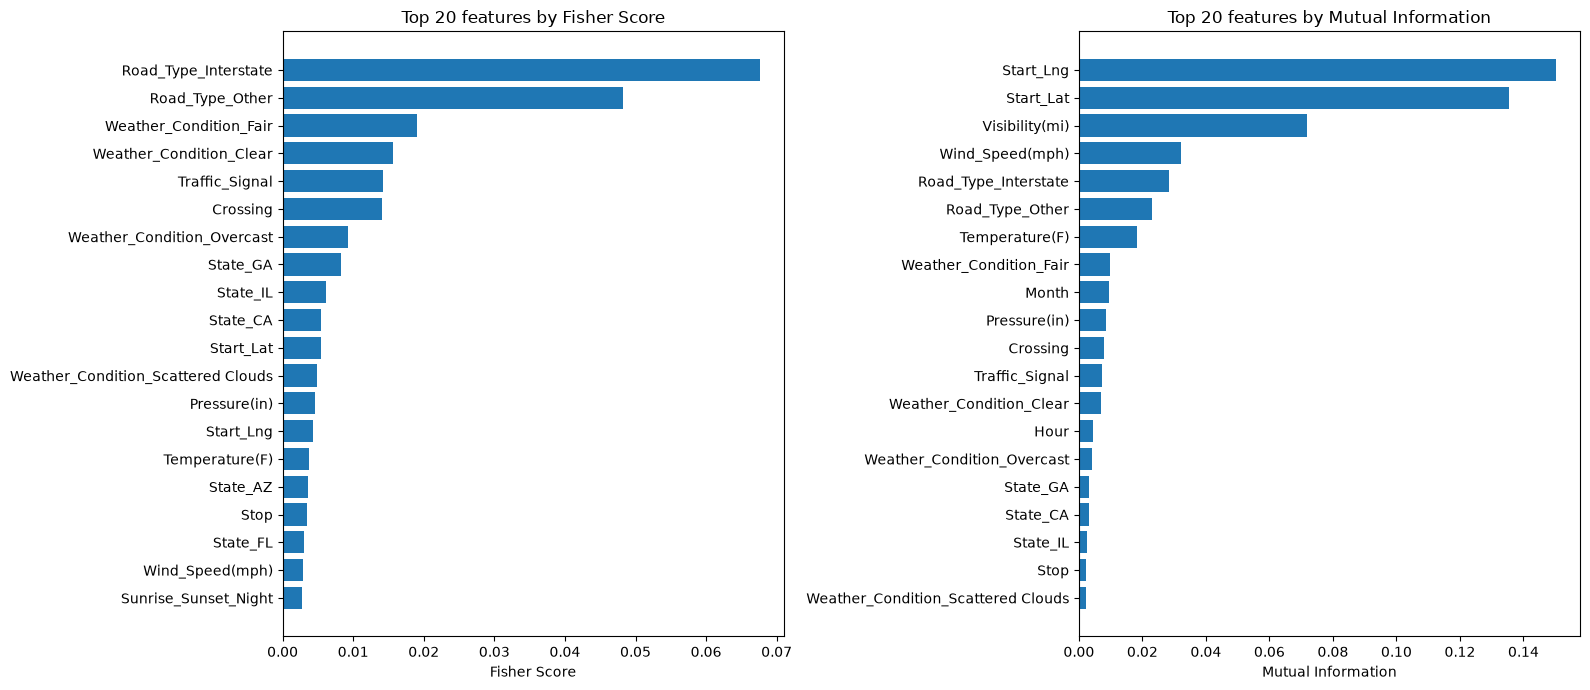

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, scores, title in [(axes[0], fisher, 'Fisher Score'), (axes[1], mi, 'Mutual Information')]:
    top = scores.head(20)[::-1]
    ax.barh(top.index, top.values)
    ax.set_title(f'Top 20 features by {title}')
    ax.set_xlabel(title)
plt.tight_layout()
plt.show()

In both Fisher Score and MI, the Road Type appears to be a very important feature. Therefore, replacing Street with the road type was probably a good idea.

Towards the bottom of the two scores are the odd weather conditions that appear rarely, as well as some States. These are the features that we should likely remove.

When actually training out model(s), we will likely choose to pick the top `k` elements by trying it out on a validation test set, however, for the sake of this assignment we will choose the top `20` features.

In [79]:
df = df[mi.head(20).index.tolist() + ['Severity']]
print(df.columns)

Index(['Start_Lng', 'Start_Lat', 'Visibility(mi)', 'Wind_Speed(mph)',
       'Road_Type_Interstate', 'Road_Type_Other', 'Temperature(F)',
       'Weather_Condition_Fair', 'Month', 'Pressure(in)', 'Crossing',
       'Traffic_Signal', 'Weather_Condition_Clear', 'Hour',
       'Weather_Condition_Overcast', 'State_GA', 'State_CA', 'State_IL',
       'Stop', 'Weather_Condition_Scattered Clouds', 'Severity'],
      dtype='str')
